<div style="background: linear-gradient(120deg, #1a3a5c 0%, #2d6a9f 60%, #4a9eda 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px;">
<img src="../Modulo III/Figures/iteso.jpg" style="height:110px; background:white; padding:6px; border-radius:8px;"/>
<div style="border-left:2px solid white; padding-left:28px; color:white;">
<h1 style="font-size:1.5em;">Ingeniería y Ciencia de Datos</h1>
<h3>Laboratorio de Procesamiento de Datos</h3>
<p>Módulo III: Selección de características: varianza y correlación</p>
</div></div>


# Introducción

En este archivo de jupyter estudiaremos **dos filtros descriptivos** para revisar columnas antes de un análisis: la varianza y la correlación. 

- Un filtro calcula una característica de los datos y ayuda a detectar columnas constantes o redundantes; no demuestra que una variable sea importante ni que mejore una predicción.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import VarianceThreshold

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})

DATA_DIR = 'Data'
FIGURES_DIR = os.path.join(DATA_DIR, 'Figures')
os.makedirs(FIGURES_DIR, exist_ok=True)


In [2]:
def mostrar_figura(nombre):
    archivo_figura = os.path.join(FIGURES_DIR, f'{nombre}.png')
    plt.show()
    plt.close()

<a id="varianza"></a>
## 1. Selección de características por varianza

Una característica con mayor varianza significa que el valor dentro de esa característica varía o tiene una cardinalidad alta. Por otro lado, una menor varianza significa que el valor dentro de la característica es similar, y una varianza cero significa que la característica tiene el mismo valor.

Intuitivamente, queremos tener una característica variada, ya que no deseamos que nuestro modelo predictivo esté sesgado. Por eso, podríamos seleccionar la característica basándonos en la varianza que seleccionamos previamente.

La selección de características por varianza es un método sencillo para eliminar características en función de la varianza esperada dentro de cada una. Sin embargo, este método presenta algunas desventajas. La selección de características mediante umbral de varianza solo considera las características de entrada (X) sin tener en cuenta la información de la variable dependiente (y). Por lo tanto, solo resulta útil para eliminar características en modelos no supervisados, no en modelos supervisados.

La **varianza** mide cuánto se dispersan los valores de una columna respecto de su media. Si casi todos los registros tienen el mismo valor, esa columna distingue poco entre observaciones. Un filtro de varianza detecta columnas constantes o de dispersión muy pequeña, **no consulta una respuesta ni demuestra utilidad para una tarea**.

Para una característica $x$ con $n$ observaciones, usaremos la varianza poblacional:

$$\operatorname{Var}(x)=\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2,\qquad \bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i.$$

Es la convención de `VarianceThreshold` y coincide con `pandas.Series.var(ddof=0)`. Si se usa `ddof=1`, se calcula una varianza muestral con denominador $n-1$ y se obtiene un valor ligeramente distinto.

#### Procedimiento paso a paso:

El proceso de uso del método del umbral de varianza comprende los siguientes pasos:

1. Calcula la varianza para cada característica del conjunto de datos.
2. Compare cada variación con el umbral predefinido.
3. Descartar las características con una varianza inferior al umbral.
4. Conservar las características con suficiente variabilidad.

Esta técnica no es supervisada , lo que significa que no tiene en cuenta las etiquetas objetivo al seleccionar las características. Es más eficaz como filtro inicial antes de aplicar métodos más complejos.

### Cómo elegir un umbral

`VarianceThreshold(t)` conserva las columnas cuya varianza es **estrictamente mayor** que $t$. El umbral 0 elimina constantes, cualquier umbral mayor también puede eliminar indicadores poco frecuentes. Reporten el umbral, las columnas eliminadas y las conservadas. Si todas las columnas quedan debajo del umbral, el filtro no tiene características que retener y se debe revisar la decisión.

La escala importa: multiplicar una medida por 1,000 multiplica su varianza por $1{,}000{,}000$. Por eso un umbral absoluto solo tiene sentido en unidades conocidas. 

Estandarizar antes de filtrar suele llevar las columnas no constantes a varianza 1 y oculta cuáles tenían poca variación original. 


In [3]:
binarias = pd.DataFrame({'constante': np.ones(100), 'rara': [1] + [0] * 99,
                         'balanceada': [0, 1] * 50, 'moderada': [1] * 10 + [0] * 90})
binarias

,constante,rara,balanceada,moderada
0,1.0,1,0,1
1,1.0,0,1,1
2,1.0,0,0,1
3,1.0,0,1,1
4,1.0,0,0,1
...,...,...,...,...
95,1.0,0,1,0
96,1.0,0,0,0
97,1.0,0,1,0
98,1.0,0,0,0


array([[<Axes: title={'center': 'constante'}>,
        <Axes: title={'center': 'rara'}>],
       [<Axes: title={'center': 'balanceada'}>,
        <Axes: title={'center': 'moderada'}>]], dtype=object)

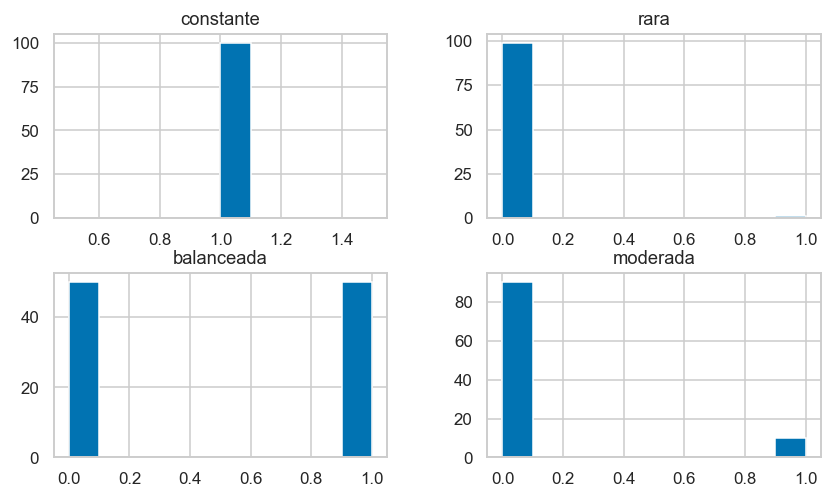

In [5]:
binarias.hist()

In [4]:
# Obtener la varianza
binarias.var(ddof=0).rename('Varianza')

constante     0.0000
rara          0.0099
balanceada    0.2500
moderada      0.0900
Name: Varianza, dtype: float64

In [6]:
help(VarianceThreshold)

Help on class VarianceThreshold in module sklearn.feature_selection._variance_threshold:

class VarianceThreshold(sklearn.feature_selection._base.SelectorMixin, sklearn.base.BaseEstimator)
 |  VarianceThreshold(threshold=0.0)
 |
 |  Feature selector that removes all low-variance features.
 |
 |  This feature selection algorithm looks only at the features (X), not the
 |  desired outputs (y), and can thus be used for unsupervised learning.
 |
 |  Read more in the :ref:`User Guide <variance_threshold>`.
 |
 |  Parameters
 |  ----------
 |  threshold : float, default=0
 |      Features with a training-set variance lower than this threshold will
 |      be removed. The default is to keep all features with non-zero variance,
 |      i.e. remove the features that have the same value in all samples.
 |
 |  Attributes
 |  ----------
 |  variances_ : array, shape (n_features,)
 |      Variances of individual features.
 |
 |  n_features_in_ : int
 |      Number of features seen during :term:`fit

In [7]:
filtro_cte = VarianceThreshold(0.0).fit(binarias)


In [9]:
binarias.columns

Index(['constante', 'rara', 'balanceada', 'moderada'], dtype='object')

In [8]:
filtro_cte.get_support()

array([False,  True,  True,  True])

In [11]:
binarias.columns[filtro_cte.get_support()]

Index(['rara', 'balanceada', 'moderada'], dtype='object')

In [12]:
# Elegimos umbrales para aplicar el filtro y aplicamos VarianceThreshold
for umbral in [0.0, 0.01, 0.10]:
    filtro_umbral = VarianceThreshold(umbral).fit(binarias)
    print('Umbral', umbral, ' Conserva las características: ', binarias.columns[filtro_umbral.get_support()].tolist())


Umbral 0.0  Conserva las características:  ['rara', 'balanceada', 'moderada']
Umbral 0.01  Conserva las características:  ['balanceada', 'moderada']
Umbral 0.1  Conserva las características:  ['balanceada']


### Ejemplo: mediciones de tumores

**Breast Cancer Wisconsin** contiene 30 mediciones numéricas de muestras celulares de tumores. Aquí **no usaremos la etiqueta de diagnóstico ni entrenaremos un clasificador**. Añadimos una columna constante y una copia de `mean radius` para ilustrar un filtro por varianza.

In [13]:
cancer = load_breast_cancer(as_frame=True)
tumores = cancer.data.copy()
tumores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [24]:
# Agregamos una nueva variable
tumores['constante'] = 1
tumores['copia_radio'] = tumores['mean radius']

#Obtenemos la varianza
varianzas_tumores = tumores.var(ddof=0).sort_values()
varianzas_tumores.head(8).rename('Varianza poblacional').to_frame()

,Varianza poblacional
constante,1.232595e-32
fractal dimension error,6.989386e-06
smoothness error,8.999270e-06
concave points error,3.800551e-05
mean fractal dimension,4.976112e-05
symmetry error,6.821281e-05
mean smoothness,1.974521e-04
compactness error,3.201393e-04


In [25]:
tumores

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,constante,copia_radio
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,1,17.99
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,1,20.57
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,1,19.69
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,1,11.42
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,1,20.29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,1,21.56
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,1,20.13
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,1,16.60
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,1,20.60


In [26]:
#Aplicamos el filtro por la varianza
filtro_var = VarianceThreshold(0).fit(tumores)

In [27]:
filtro_var.get_support()

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False,  True])

In [28]:
#Obtener el filtro

In [29]:
#Columnas filtradas
tumores.columns[filtro_var.get_support()]

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'copia_radio'],
      dtype='object')

In [30]:
tumores_var = tumores.loc[:,tumores.columns[filtro_var.get_support()]]
tumores_var

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,copia_radio
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,17.99
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,20.57
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,19.69
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,11.42
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,20.29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,21.56
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,20.13
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,16.60
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,20.60


In [21]:
varianzas_tumores

constante                  1.232595e-32
fractal dimension error    6.989386e-06
smoothness error           8.999270e-06
concave points error       3.800551e-05
mean fractal dimension     4.976112e-05
symmetry error             6.821281e-05
mean smoothness            1.974521e-04
compactness error          3.201393e-04
worst fractal dimension    3.256361e-04
worst smoothness           5.204036e-04
mean symmetry              7.502220e-04
concavity error            9.095968e-04
mean concave points        1.503015e-03
mean compactness           2.784285e-03
worst symmetry             3.820857e-03
worst concave points       4.313147e-03
mean concavity             6.344079e-03
worst compactness          2.471126e-02
worst concavity            4.344760e-02
radius error               7.676720e-02
texture error              3.037811e-01
perimeter error            4.080711e+00
mean radius                1.239709e+01
copia_radio                1.239709e+01
mean texture               1.846640e+01


In [22]:
#Columnas eliminadas por varianza
filtro_var = VarianceThreshold(0.1).fit(tumores)
tumores.columns[filtro_var.get_support()]

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'texture error', 'perimeter error', 'area error', 'worst radius',
       'worst texture', 'worst perimeter', 'worst area', 'copia_radio'],
      dtype='object')

## Casos de uso y aplicaciones

- Clasificación de texto: Los datos dispersos de alta dimensión (por ejemplo, vectores TF-IDF ) suelen contener muchas características con varianza nula o baja.
- Bioinformática: Los datos genómicos contienen miles de niveles de expresión génica, muchos de los cuales varían poco.
- Redes de sensores: Las lecturas de los sensores pueden permanecer constantes durante largos períodos, lo que introduce características de baja varianza.
- En todos estos ámbitos, la aplicación del umbral de varianza puede reducir el ruido y el tiempo de cálculo.

#### Ventajas y limitaciones

##### Ventajas
- Sencillez: Muy fácil de entender e implementar.
- Velocidad: Computacionalmente eficiente incluso con grandes conjuntos de datos.
- Utilidad de preprocesamiento: Útil como primer paso en el proceso de selección de características.

##### Limitaciones
- Ignora la variable objetivo: No puede evaluar la relevancia de una característica con respecto al resultado.
- No es eficaz para todas las características de baja varianza: algunas características de baja varianza aún podrían ser importantes para la clasificación .
- Falla con características redundantes: No puede detectar la multicolinealidad ni las características correlacionadas con alta varianza.

<a id="correlacion"></a>
## 2. Selección de características por correlación

La **correlación** resume la intensidad y dirección de una asociación entre dos columnas. Se usa para detectar posibles redundancias: si dos variables numéricas contienen información muy parecida, el equipo puede decidir conservar una por razones de interpretación, costo o facilidad de medición.

La correlación de **Pearson** mide asociación **lineal**:

$$r_{xy}=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i(x_i-\bar x)^2\sum_i(y_i-\bar y)^2}}.$$

Su valor está entre -1 y 1. Un valor cercano a 1 indica asociación lineal positiva, cerca de -1, negativa, cerca de 0, poca asociación **lineal** en los datos observados. 

**Spearman** calcula Pearson sobre los rangos. Detecta una relación monótona aunque no sea lineal y reduce la influencia de la escala de valores extremos. No detecta cualquier dependencia: si la asociación tiene forma de U, puede resultar cercana a cero.

### Regla de filtrado por pares

Una estrategia sencilla calcula $|r|$ para cada par y, si supera un umbral como 0.85 o 0.90, elimina una de las dos columnas. La función de abajo usa un recorrido voraz y el orden de las columnas: conserva la primera y descarta las siguientes que excedan el umbral frente a alguna ya retenida. Por tanto, cambiar el orden puede cambiar qué variable se conserva.

El umbral no es una ley natural. Correlación alta sugiere redundancia por pares, pero no garantiza equivalencia, correlación baja no prueba independencia. Una constante tiene correlación indefinida, así que debe identificarse antes.

### Ejemplo conceptual: correlación cero con dependencia

Para $x=(-2,-1,0,1,2)$ y $z=x^2=(4,1,0,1,4)$, Pearson es cero: los productos positivos y negativos se cancelan por simetría. Sin embargo, al conocer x se conoce z exactamente. 

En la práctica con mediciones celulares, añadimos deliberadamente una copia exacta de `mean radius`. Esperamos que el filtro retire una de esas dos columnas, pero **no entrenaremos modelos** ni usaremos clases diagnósticas para decidir. La actividad es exploratoria.

In [31]:
#Dataset ya después de aplicarle el filtro de varianzas tumores_var
tumores_var.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [32]:
# Obtenemos la correlación de pearson
matriz = tumores_var.corr(method='pearson')
matriz

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,copia_radio
mean radius,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631,...,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066,1.000000
mean texture,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437,...,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205,0.323782
mean perimeter,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477,...,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019,0.997855
mean area,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110,...,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738,0.987357
mean smoothness,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792,...,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316,0.170581
mean compactness,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369,...,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382,0.506124
mean concavity,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783,...,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930,0.676764
mean concave points,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917,...,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661,0.822529
mean symmetry,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921,...,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413,0.147741
mean fractal dimension,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000,...,-0.051269,-0.205151,-0.231854,0.504942,0.458798,0.346234,0.175325,0.334019,0.767297,-0.311631


<Axes: >

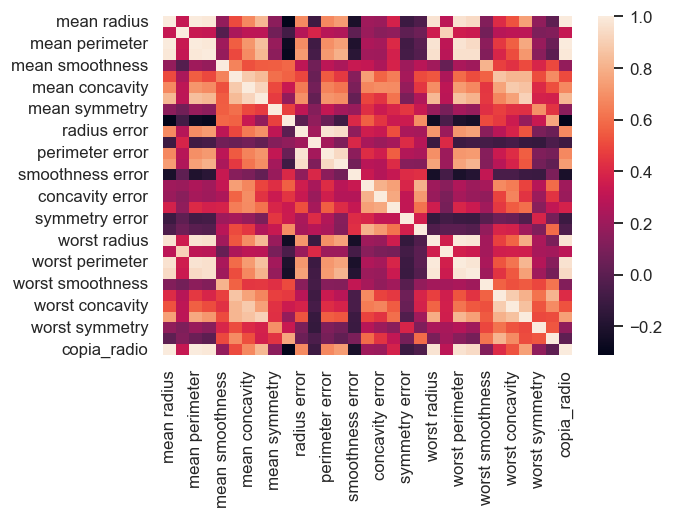

In [33]:
fig, ax = plt.subplots()
fig.set_size_inches(6,4)
sns.heatmap(matriz)

In [34]:
#Función para seleccionar las características correlacionada
def seleccionar_correlacion(datos, umbral=0.90, metodo='pearson'):
    matriz = datos.corr(method=metodo).abs()
    conservadas = []
    for columna in datos.columns:
        if not conservadas or not (matriz.loc[columna, conservadas] > umbral).any():
            conservadas.append(columna)
    return conservadas

In [37]:
tumores_var.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'copia_radio'],
      dtype='object')

In [36]:
# columnas correlacionadas con umbral
columnas_cor = seleccionar_correlacion(tumores_var, umbral = 0.9, metodo='pearson')
columnas_cor

['mean radius',
 'mean texture',
 'mean smoothness',
 'mean compactness',
 'mean concavity',
 'mean symmetry',
 'mean fractal dimension',
 'radius error',
 'texture error',
 'smoothness error',
 'compactness error',
 'concavity error',
 'concave points error',
 'symmetry error',
 'fractal dimension error',
 'worst smoothness',
 'worst compactness',
 'worst concavity',
 'worst concave points',
 'worst symmetry',
 'worst fractal dimension']

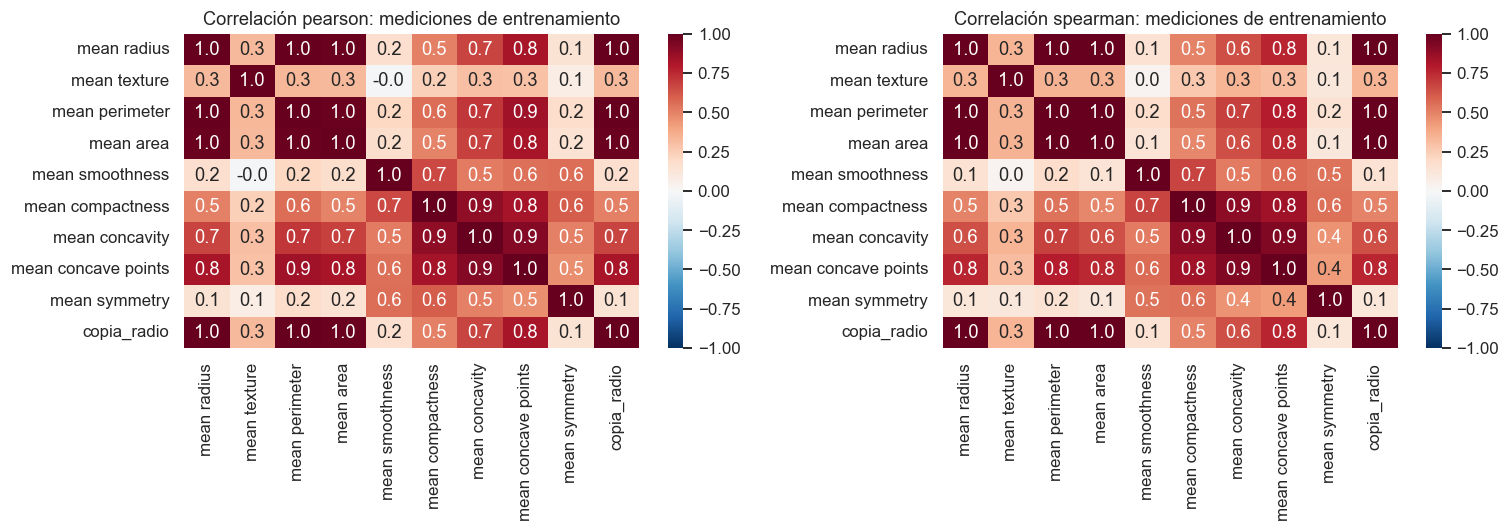

In [38]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
primeras = list(tumores_var.columns[:9]) + ['copia_radio']
for eje, metodo in zip(ejes, ['pearson', 'spearman']):
    matriz = tumores_var[primeras].corr(method=metodo)
    sns.heatmap(matriz, vmin=-1, vmax=1, center=0, cmap='RdBu_r', annot=True, fmt='.1f', ax=eje)
    eje.set_title(f'Correlación {metodo}: mediciones de entrenamiento')
fig.tight_layout()
mostrar_figura('04_correlaciones')

In [41]:
tumores_cor = tumores_var.loc[:, columnas_cor]
tumores_cor

,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,mean symmetry,mean fractal dimension,radius error,texture error,smoothness error,...,concavity error,concave points error,symmetry error,fractal dimension error,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,0.11840,0.27760,0.30010,0.2419,0.07871,1.0950,0.9053,0.006399,...,0.05373,0.01587,0.03003,0.006193,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,0.08474,0.07864,0.08690,0.1812,0.05667,0.5435,0.7339,0.005225,...,0.01860,0.01340,0.01389,0.003532,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,0.10960,0.15990,0.19740,0.2069,0.05999,0.7456,0.7869,0.006150,...,0.03832,0.02058,0.02250,0.004571,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,0.14250,0.28390,0.24140,0.2597,0.09744,0.4956,1.1560,0.009110,...,0.05661,0.01867,0.05963,0.009208,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,0.10030,0.13280,0.19800,0.1809,0.05883,0.7572,0.7813,0.011490,...,0.05688,0.01885,0.01756,0.005115,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,0.11100,0.11590,0.24390,0.1726,0.05623,1.1760,1.2560,0.010300,...,0.05198,0.02454,0.01114,0.004239,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,0.09780,0.10340,0.14400,0.1752,0.05533,0.7655,2.4630,0.005769,...,0.03950,0.01678,0.01898,0.002498,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,0.08455,0.10230,0.09251,0.1590,0.05648,0.4564,1.0750,0.005903,...,0.04730,0.01557,0.01318,0.003892,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,0.11780,0.27700,0.35140,0.2397,0.07016,0.7260,1.5950,0.006522,...,0.07117,0.01664,0.02324,0.006185,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [42]:
comparacion_filtros = pd.DataFrame([
    {'etapa': 'Características iniciales', 'columnas': tumores.shape[1],
     'columnas retiradas en esta etapa': 0},
    {'etapa': 'Después de retirar varianza cero', 'columnas': tumores_var.shape[1],
     'columnas retiradas en esta etapa': tumores.shape[1] - tumores_var.shape[1]},
    {'etapa': 'Después del filtro Pearson |r| > 0.90', 'columnas': tumores_cor.shape[1],
     'columnas retiradas en esta etapa': tumores_var.shape[1] - tumores_cor.shape[1]},
])
comparacion_filtros

,etapa,columnas,columnas retiradas en esta etapa
0,Características iniciales,32,0
1,Después de retirar varianza cero,31,1
2,Después del filtro Pearson |r| > 0.90,21,10


# Práctica de laboratorio: variabilidad y relaciones en vinos tintos


In [43]:
CARPETA_VINO = os.path.join('Data')
ARCHIVO_VINO = os.path.join(CARPETA_VINO, 'winequality-red.csv')

vino = pd.read_csv(ARCHIVO_VINO, sep=';')
vino.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [44]:
print('Dimensiones:', vino.shape)
print('Columnas:', vino.columns.tolist())


Dimensiones: (1599, 12)
Columnas: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [45]:
print('Celdas faltantes:', int(vino.isna().sum().sum()))
print('Filas duplicadas:', int(vino.duplicated().sum()))
display(vino['quality'].value_counts().sort_index().rename_axis('quality').to_frame('muestras'))


Celdas faltantes: 0
Filas duplicadas: 240


,muestras
quality,
3,10
4,53
5,681
6,638
7,199
8,18


####  Varianza de las mediciones

Separaremos las 11 mediciones fisicoquímicas de `quality`. Primero observaremos varianza y escala de cada característica. Luego compararemos tres umbrales sobre los valores originales. El umbral 0 busca constantes; 0.01 y 0.1 son ejemplos para explorar, **no recomendaciones universales**.

La diferencia de magnitudes entre columnas importa: comparar directamente la varianza de `density` con la de `total sulfur dioxide` puede reflejar sobre todo sus unidades. Por eso, esta tabla sirve para inspeccionar y practicar, no para declarar irrelevante una medida basándose únicamente en una varianza pequeña.

Al final estandarizaremos solo para ilustrar el efecto en las varianzas. Si todas las características se centran y escalan, `VarianceThreshold` deja de distinguir su variabilidad original. No usaremos esta estandarización para entrenar un modelo.

In [46]:
from sklearn.preprocessing import StandardScaler

objetivo_vino = 'quality'
caracteristicas_vino = vino.drop(columns=[objetivo_vino])
varianzas_vino = caracteristicas_vino.var(ddof=0).sort_values()

resumen_varianzas_vino = pd.DataFrame({
    'varianza_poblacional': varianzas_vino,
    'desviacion_estandar': caracteristicas_vino.std(ddof=0).reindex(varianzas_vino.index),
    'minimo': caracteristicas_vino.min().reindex(varianzas_vino.index),
    'maximo': caracteristicas_vino.max().reindex(varianzas_vino.index)
})
resumen_varianzas_vino.round(5)


,varianza_poblacional,desviacion_estandar,minimo,maximo
density,0.00000,0.00189,0.99007,1.00369
chlorides,0.00221,0.04705,0.01200,0.61100
pH,0.02382,0.15434,2.74000,4.01000
sulphates,0.02871,0.16945,0.33000,2.00000
volatile acidity,0.03204,0.17900,0.12000,1.58000
citric acid,0.03792,0.19474,0.00000,1.00000
alcohol,1.13494,1.06533,8.40000,14.90000
residual sugar,1.98665,1.40949,0.90000,15.50000
fixed acidity,3.02952,1.74055,4.60000,15.90000
free sulfur dioxide,109.34646,10.45689,1.00000,72.00000


In [47]:
for umbral_vino in [0, 0.01, 0.10]:
    filtro_vino = VarianceThreshold(threshold=umbral_vino).fit(caracteristicas_vino)
    retenidas = caracteristicas_vino.columns[filtro_vino.get_support()].tolist()
    eliminadas = caracteristicas_vino.columns[~filtro_vino.get_support()].tolist()
    print(f'Umbral {umbral_vino}: conserva {len(retenidas)}; elimina {eliminadas}')



Umbral 0: conserva 11; elimina []
Umbral 0.01: conserva 9; elimina ['chlorides', 'density']
Umbral 0.1: conserva 5; elimina ['volatile acidity', 'citric acid', 'chlorides', 'density', 'pH', 'sulphates']


In [48]:
escalador_vino = StandardScaler().fit(caracteristicas_vino)
vino_estandarizado = pd.DataFrame(escalador_vino.transform(caracteristicas_vino),
                                  columns=caracteristicas_vino.columns)

vino_estandarizado.var(ddof=0).rename('varianza_tras_estandarizar').to_frame().round(5)

,varianza_tras_estandarizar
fixed acidity,1.0
volatile acidity,1.0
citric acid,1.0
residual sugar,1.0
chlorides,1.0
free sulfur dioxide,1.0
total sulfur dioxide,1.0
density,1.0
pH,1.0
sulphates,1.0


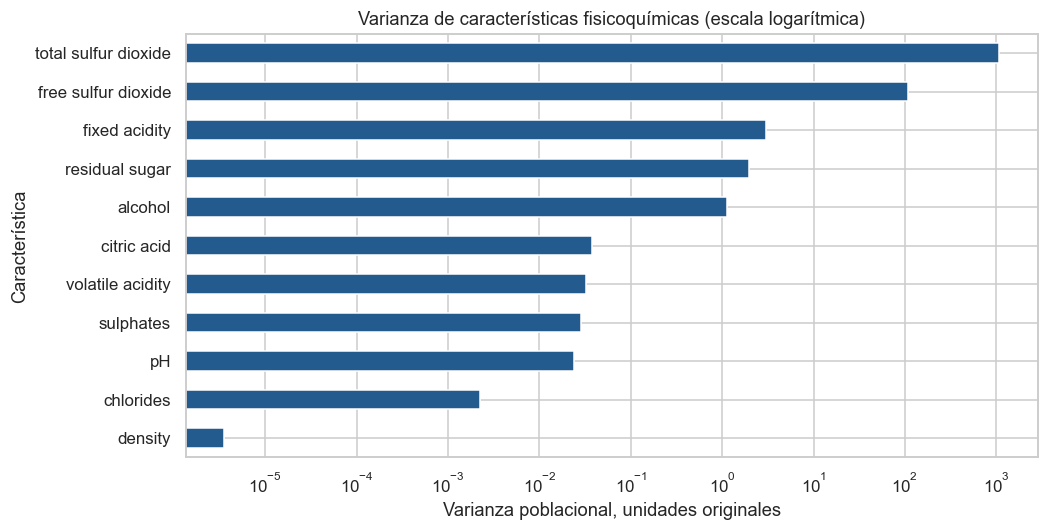

In [49]:
fig, eje = plt.subplots(figsize=(10, 5))
varianzas_vino.sort_values().plot.barh(ax=eje, color='#245b8f')
eje.set_xscale('log')
eje.set(title='Varianza de características fisicoquímicas (escala logarítmica)',
       xlabel='Varianza poblacional, unidades originales', ylabel='Característica')
mostrar_figura('06_varianza_vino_uci')

#### Correlación entre mediciones del vino

Ahora calcularemos Pearson y Spearman únicamente entre las once variables fisicoquímicas. La puntuación `quality` no se incluye en el filtro de características. Después la compararemos descriptivamente con algunas mediciones para practicar la lectura de asociaciones, **sin entrenar un modelo**.

La selección de pares con $|r|>0.85$ es una regla de demostración. Revisen la matriz antes de retirar una variable: una asociación alta puede señalar medidas redundantes, pero se conserva la que tenga más sentido para la pregunta, interpretación o calidad de medición. Cambiar el umbral puede cambiar cuántas columnas quedan.

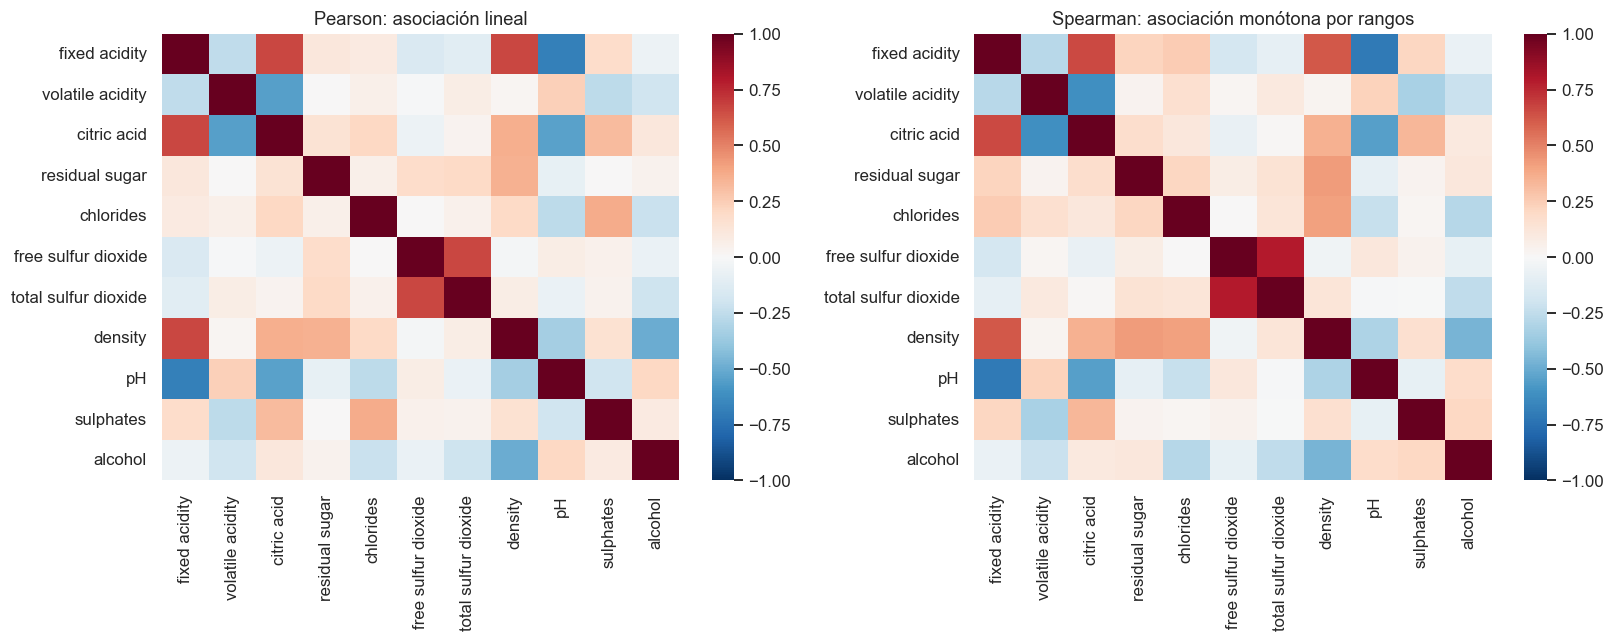

In [50]:
correlaciones_pearson_vino = caracteristicas_vino.corr(method='pearson')
correlaciones_spearman_vino = caracteristicas_vino.corr(method='spearman')
fig, ejes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(correlaciones_pearson_vino, vmin=-1, vmax=1, center=0, cmap='RdBu_r', ax=ejes[0])
ejes[0].set_title('Pearson: asociación lineal')
sns.heatmap(correlaciones_spearman_vino, vmin=-1, vmax=1, center=0, cmap='RdBu_r', ax=ejes[1])
ejes[1].set_title('Spearman: asociación monótona por rangos')
fig.tight_layout()
mostrar_figura('07_correlacion_vino_uci')


In [51]:
mascara_superior = np.triu(np.ones(correlaciones_pearson_vino.shape, dtype=bool), k=1)
pares_pearson_vino = correlaciones_pearson_vino.abs().where(mascara_superior).stack().sort_values(ascending=False)
pares_pearson_vino.index.names = ['variable_1', 'variable_2']
print('Diez pares con mayor |Pearson| entre características:')
pares_pearson_vino.head(10).rename('|Pearson|').to_frame()


Diez pares con mayor |Pearson| entre características:


|Pearson|
variable_1          variable_2                     
fixed acidity       pH                     0.682978
                    citric acid            0.671703
                    density                0.668047
free sulfur dioxide total sulfur dioxide   0.667666
volatile acidity    citric acid            0.552496
citric acid         pH                     0.541904
density             alcohol                0.496180
chlorides           sulphates              0.371260
citric acid         density                0.364947
residual sugar      density                0.355283

In [52]:
tabla_umbral_vino = []
for umbral in [0.85, 0.90, 0.95]:
    retenidas = seleccionar_correlacion(caracteristicas_vino, umbral=umbral, metodo='pearson')
    tabla_umbral_vino.append({'umbral |Pearson|': umbral, 'columnas retenidas': len(retenidas),
                              'columnas excluidas': len(caracteristicas_vino.columns) - len(retenidas),
                              'excluidas': ', '.join(columna for columna in caracteristicas_vino if columna not in retenidas)})
pd.DataFrame(tabla_umbral_vino)

relacion_quality = vino.corr(method='spearman')['quality'].drop('quality').sort_values()
relacion_quality.rename('Spearman descriptivo con quality').to_frame()

,Spearman descriptivo con quality
volatile acidity,-0.380647
total sulfur dioxide,-0.196735
chlorides,-0.189922
density,-0.177074
free sulfur dioxide,-0.056901
pH,-0.043672
residual sugar,0.032048
fixed acidity,0.114084
citric acid,0.213481
sulphates,0.377060
